<a href="https://colab.research.google.com/github/jojojojo-jo/LRP_analysis_resnet/blob/main/LRP_clean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#0. Import

Zennit: https://zennit.readthedocs.io/en/latest/tutorial/image-classification-vgg-resnet.html#4.3-LRP-with-custom-LayerMapComposite

In [ ]:
!pip install torch==2.9.0 torchvision==0.24.0 torchaudio==2.9.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 899.7/899.7 MB 625.8 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 98.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.7/124.7 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.5/170.5 MB 6.9 MB/s eta 0:00:00
  Attempting uninstall: triton
    Found existing installation: triton 3.6.0
    Uninstalling triton-3.6.0:
      Successfully uninstalled triton-3.6.0
  Attempting uninstall: nvidia-nvshmem-cu12
    Found existing installation: nvidia-nvshmem-cu12 3.4.5
    Uninstalling nvidia-nvshmem-cu12-3.4.5:
      Successfully uninstalled nvidia-nvshmem-cu12-3.4.5
  Attempting uninstall: torch
    Found existing installation: torch 2.10.0+cu128
    Uninstalling torch-2.10.0+cu128:
      Successfully uninstalled torch-2.10.0+cu128
  Attempting uninstall: torchvision
    Found existing installation: torchvision 0.25.0+cu128
    Uninstalling torchvision-0.25.0+cu128:
      Successfully u

In [ ]:
!pip install zennit

In [ ]:
import torch
from torch import nn
from torch.nn import Linear
import torch.nn.functional as F

from itertools import islice

from PIL import Image

import torchvision
from torchvision import datasets, models, transforms
from torchvision.transforms import Compose, Resize, CenterCrop
from torchvision.transforms import ToTensor, Normalize
from torchvision.models import resnet18
from torchvision.models import ResNet18_Weights

from zennit.attribution import Gradient, SmoothGrad
from zennit.core import Stabilizer
from zennit.composites import EpsilonGammaBox, EpsilonPlusFlat
from zennit.composites import SpecialFirstLayerMapComposite, NameMapComposite
from zennit.image import imgify, imsave
from zennit.rules import Epsilon, ZPlus, ZBox, Norm, Pass, Flat
from zennit.types import Convolution, Activation, AvgPool, Linear as AnyLinear
from zennit.types import BatchNorm
from zennit.torchvision import ResNetCanonizer

import os
import numpy as np
import matplotlib.pyplot as plt

#import torchinfo.summary
try:
  from torchinfo import summary
except:
  print("[INFO] Couldn't find torchinfo... installing it")
  !pip install -q torchinfo
  from torchinfo import summary

#import helper functions
try:
  from going_modular.going_modular import data_setup, engine
except:
  print(f"[INFO] Couldn't find going_modular scripts... downloading from GitHub")
  !git clone https://github.com/mrdbourke/pytorch-deep-learning
  !mv pytorch-deep-learning/going_modular .
  !rm -rf pytorch-deep-learning
  from going_modular.going_modular import data_setup, engine

In [ ]:
print(torch.__version__)

2.9.0+cu128


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

#1. Get data

In [ ]:
import os
import zipfile

from pathlib import Path

import requests

data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi_20_percent"

if image_path.is_dir():
  print(f"{image_path} directory exists")
else:
  print(f"Did not find {image_path} directory, creating one...")
  image_path.mkdir(parents=True, exist_ok=True)

  with open(data_path / "pizza_steak_sushi_20_percent.zip", "wb") as f:
    request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi_20_percent.zip")
    print("Downloading data...")
    f.write(request.content)

  with zipfile.ZipFile(data_path / "pizza_steak_sushi_20_percent.zip", "r") as zip_ref:
    print("Unzipping data...")
    zip_ref.extractall(image_path)

  os.remove(data_path / "pizza_steak_sushi_20_percent.zip")

Did not find data/pizza_steak_sushi_20_percent directory, creating one...
Unzipping data...


In [ ]:
train_dir = image_path / "train"
test_dir = image_path / "test"

train_dir, test_dir

(PosixPath('data/pizza_steak_sushi_20_percent/train'),
 PosixPath('data/pizza_steak_sushi_20_percent/test'))

In [ ]:
from numpy.matrixlib import test

weights = torchvision.models.ResNet18_Weights.DEFAULT
auto_transforms = weights.transforms()
print(f"Automatically created transforms: {auto_transforms}")

train_dataset = datasets.ImageFolder(train_dir, transform=auto_transforms)
test_dataset = datasets.ImageFolder(test_dir, transform=auto_transforms)
train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(train_dir=train_dir,
                                                                               test_dir=test_dir,
                                                                               transform=auto_transforms,
                                                                               batch_size=32)
train_dataloader, test_dataloader, class_names

Automatically created transforms: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


(<torch.utils.data.dataloader.DataLoader at 0x7963e57e2270>,
 ['pizza', 'steak', 'sushi'])

#2. Load model

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
torch.manual_seed(42)

weights = torchvision.models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)
for param in model.parameters():
    param.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, len(class_names))

model_path = '/content/drive/MyDrive/study/Project/models/best_model_plateau.pth'
model.load_state_dict(torch.load(model_path, map_location=torch.device('cpu')))
model = model.to(device)

model.eval()

print("Model loaded successfully!")

Model loaded successfully!


#3. Generate LRP Heatmap

In [ ]:
# define the base image transform
transform_img = Compose([
    Resize(256),
    CenterCrop(224),
])
# define the normalization transform
transform_norm = Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
# define the full tensor transform
transform = Compose([
    transform_img,
    ToTensor(),
    transform_norm,
])

# load the image
image = Image.open('sushi1.jpg')

# transform the PIL image and insert a batch-dimension
data = transform(image)[None]

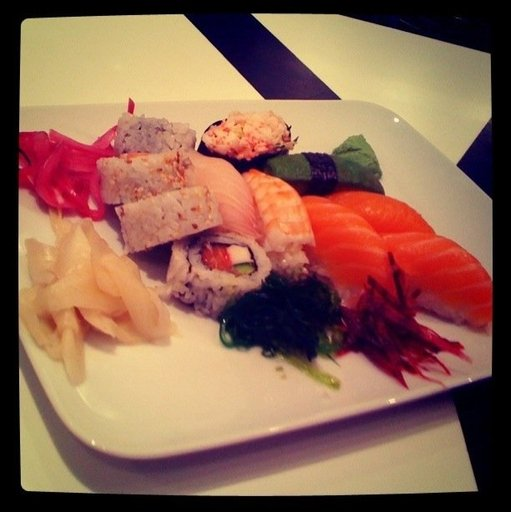

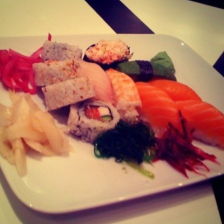

In [ ]:
display(image)
display(transform_img(image))

In [ ]:
!rm -rf output

In [ ]:
from pathlib import Path
import torch
from PIL import Image

# --- Configuration ---
input_base_dir = Path('data/pizza_steak_sushi_20_percent')
output_base_dir = Path('output')

class_to_idx = {'pizza': 0, 'steak': 1, 'sushi': 2}
idx_to_class = {v: k for k, v in class_to_idx.items()}

# Device setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)
model.eval()

# Reusing your canonizer logic
canonizer = ResNetCanonizer()
composite = EpsilonPlusFlat(canonizers=[canonizer])

# --- Processing Loop ---
# Keep the Attributor context outside the loops for maximum performance
with Gradient(model=model, composite=composite) as attributor:

    for split in ['train', 'test']:
        for folder_class, class_idx in class_to_idx.items():

            source_dir = input_base_dir / split / folder_class
            if not source_dir.exists():
                continue

            # Filter for valid image file extensions
            img_paths = [p for p in source_dir.glob('*') if p.suffix.lower() in ['.jpg', '.jpeg', '.png']]

            for img_path in img_paths:
                try:
                    # 1. Load Clean Image Baseline
                    image = Image.open(img_path)
                    data = transform(image)[None].to(device)

                    # 2. Extract the Model's Clean Prediction Target
                    with torch.no_grad():
                        output = model(data)

                    # Extract the prediction index as a standard scalar integer
                    pred_int = output.argmax(1).item()
                    pred_class_name = idx_to_class[pred_int]

                    # 3. Create a Zennit-compliant One-Hot Target Tensor
                    target_tensor = torch.eye(len(class_to_idx), device=device)[[pred_int]]

                    # 4. Generate Baseline Attribution (S_orig)
                    output, attribution = attributor(data, target_tensor)

                    # 5. Process Heatmap
                    # Sum across color channels and shift back to CPU for image creation
                    relevance = attribution.sum(1).cpu()
                    heatmap_img = imgify(relevance, symmetric=True, cmap='coldnhot')

                    # 6. Save Organized Outputs
                    target_dir = output_base_dir / split / folder_class
                    target_dir.mkdir(parents=True, exist_ok=True)

                    # Naming format encodes the original image name and what class the heatmap targeted
                    save_path = target_dir / f"heatmap_{img_path.name}"
                    heatmap_img.convert('RGB').save(save_path)

                    print(f"Processed: {split}/{folder_class}/{img_path.name} | Predicted: {pred_class_name}")

                except Exception as e:
                    print(f"Error processing {img_path}: {e}")

print("All heatmaps generated successfully.")

Processed: train/pizza/3693710.jpg | Predicted: pizza
Processed: train/pizza/300869.jpg | Predicted: pizza
Processed: train/pizza/3821701.jpg | Predicted: steak
Processed: train/pizza/656817.jpg | Predicted: pizza
Processed: train/pizza/1412034.jpg | Predicted: pizza
Processed: train/pizza/1065078.jpg | Predicted: pizza
Processed: train/pizza/2702825.jpg | Predicted: pizza
Processed: train/pizza/1029698.jpg | Predicted: pizza
Processed: train/pizza/3082068.jpg | Predicted: pizza
Processed: train/pizza/3391208.jpg | Predicted: pizza
Processed: train/pizza/3401720.jpg | Predicted: pizza
Processed: train/pizza/3128495.jpg | Predicted: pizza
Processed: train/pizza/2760984.jpg | Predicted: pizza
Processed: train/pizza/2291093.jpg | Predicted: pizza
Processed: train/pizza/220190.jpg | Predicted: pizza
Processed: train/pizza/910419.jpg | Predicted: pizza
Processed: train/pizza/3766476.jpg | Predicted: pizza
Processed: train/pizza/2529205.jpg | Predicted: pizza
Processed: train/pizza/2742044.j




In [ ]:
import random

def display_pairs(input_dir='data/pizza_steak_sushi_20_percent/test', output_dir='output/test', num_pairs=5):
    # 1. Get a list of all input images
    input_files = list(Path(input_dir).rglob('*.jpg')) + list(Path(input_dir).rglob('*.png'))

    # 2. Select a random sample
    sample_size = min(num_pairs, len(input_files))
    selected_inputs = random.sample(input_files, sample_size)

    # 3. Create the plot
    fig, axes = plt.subplots(sample_size, 2, figsize=(10, 5 * sample_size))

    # Handle case where sample_size is 1 (axes array shape issues)
    if sample_size == 1:
        axes = [axes]

    for i, input_path in enumerate(selected_inputs):
        # Construct path to the respective output
        # e.g., data/train/pizza/123.jpg -> heatmaps_output/train/pizza/123.jpg
        relative_path = input_path.relative_to(Path(input_dir))
        expected_filename = f"heatmap_{input_path.name}"
        output_path = output_dir / relative_path.parent / expected_filename

        original_image = Image.open(input_path)
        transformed_image = transform_img(original_image)

        #get Pred and Prob
        model.eval()
        with torch.inference_mode():
          #Transform and add an extra dimension to image (model requires samples in [batch_size, color_channels, height, width])
          transformed_image_pred = transform(original_image).unsqueeze(dim=0)

          #Make a prediction on image with an extra dimension and send it to the target device
          target_image_pred = model(transformed_image_pred.to(device))

        #Convert logits -> prediction probabilities (using torch.softmax() for multi-class classification)
        target_image_pred_probs = torch.softmax(target_image_pred, dim=1)

        #Convert prediction probabilities -> prediction labels
        target_image_pred_label = torch.argmax(target_image_pred_probs, dim=1)

        # Plot Input
        axes[i][0].imshow(transformed_image)
        axes[i][0].set_title(f"Input: {input_path.name} | Pred: {class_names[target_image_pred_label]} ({target_image_pred_probs.max():.3f})")
        axes[i][0].axis('off')

        # Plot Output
        if output_path.exists():
          axes[i][1].imshow(Image.open(output_path))
          axes[i][1].set_title(f"Output: {output_path.name}")
        else:
          axes[i][1].text(0.5, 0.5, 'Heatmap not found')

    plt.tight_layout()
    plt.show()

# Run it
display_pairs(num_pairs=30)

#4. Save output


In [ ]:
from google.colab import drive
drive.mount('/content/drive' , force_remount=True)

Mounted at /content/drive


In [ ]:
import shutil

shutil.make_archive('output', 'zip', root_dir='.', base_dir='output')
print("Folder zipped")

source_path = 'output.zip'
destination_path = '/content/drive/MyDrive/study/Project/LRP_Heatmap/clean_heatmap/output_updated'
shutil.copy(source_path, destination_path)

Folder zipped


'/content/drive/MyDrive/study/Project/LRP_Heatmap/clean_heatmap/output_updated/output.zip'